# AICS-202 | Laboratory 02
## FGSM Evasion Testing in a Local Sandbox
Course module: 2 | Suggested duration: 4 hours

**Objective:** generate and measure controlled adversarial examples against a classifier you own. Only the local scikit-learn digits data are used.

**Assumption:** white-box access to the locally trained logistic regression model. Results do not generalise automatically to different architectures.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
digits = load_digits()
X = digits.data.astype(float) / 16.0
y = digits.target.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

def build_model(train_features, train_labels):
    model = LogisticRegression(max_iter=600, random_state=SEED)
    model.fit(train_features, train_labels)
    return model

model = build_model(X_train, y_train)
print('Dataset:', X.shape, '| Train:', len(X_train), '| Test:', len(X_test))
print('Clean test accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 4))

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622


### Part A - Compute the input gradient and FGSM perturbation
Use the gradient of cross-entropy with respect to the normalised image input.

In [2]:
def input_loss_gradient(model, features, labels):
    """Cross-entropy gradient with respect to input, for multinomial logistic regression."""
    probs = model.predict_proba(features)
    targets = np.zeros_like(probs)
    label_indices = np.searchsorted(model.classes_, labels)
    targets[np.arange(len(labels)), label_indices] = 1.0
    return (probs - targets) @ model.coef_

def fgsm(model, features, labels, epsilon=0.10):
    grad = input_loss_gradient(model, features, labels)
    return np.clip(features + epsilon * np.sign(grad), 0.0, 1.0)

Epsilon=0.00 | Accuracy=0.962
Epsilon=0.03 | Accuracy=0.907
Epsilon=0.07 | Accuracy=0.791
Epsilon=0.12 | Accuracy=0.516
Epsilon=0.18 | Accuracy=0.204


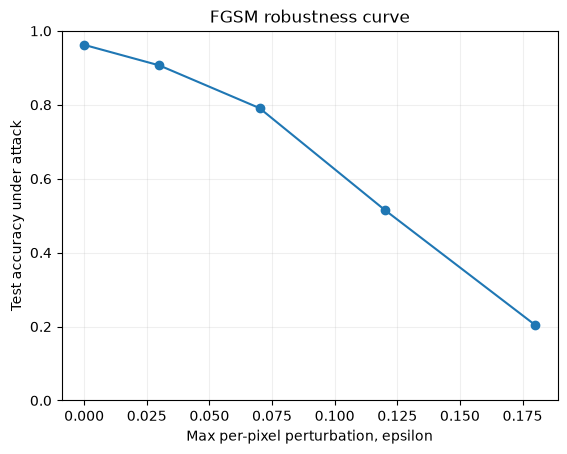

In [3]:
epsilons = [0.00, 0.03, 0.07, 0.12, 0.18]
results = []
for eps in epsilons:
    changed = fgsm(model, X_test, y_test, epsilon=eps)
    acc = accuracy_score(y_test, model.predict(changed))
    results.append((eps, acc))
    print(f'Epsilon={eps:0.2f} | Accuracy={acc:.3f}')
plt.plot([p[0] for p in results], [p[1] for p in results], marker='o')
plt.xlabel('Max per-pixel perturbation, epsilon')
plt.ylabel('Test accuracy under attack')
plt.title('FGSM robustness curve')
plt.ylim(0, 1); plt.grid(alpha=.2); plt.show()

### Part B - Display clean and adversarial samples

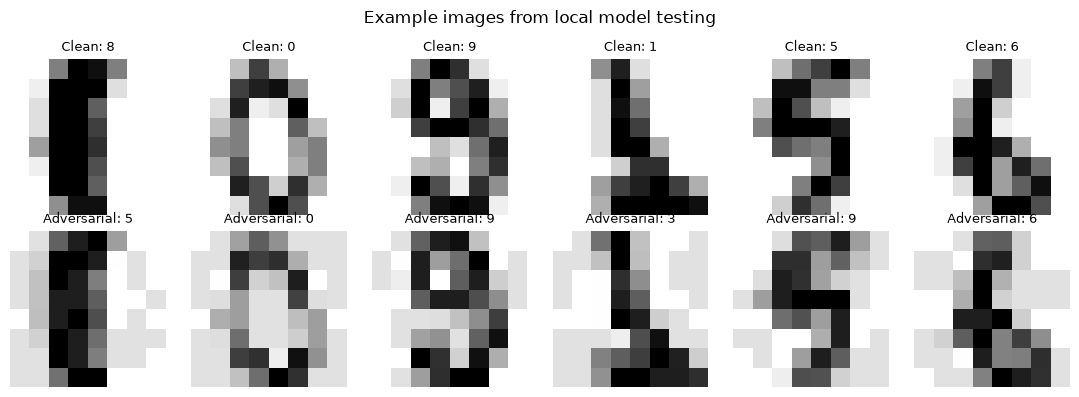

Max observed L-infinity change: 0.12


In [4]:
epsilon = 0.12
adversarial = fgsm(model, X_test, y_test, epsilon=epsilon)
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for j in range(6):
    axes[0, j].imshow(X_test[j].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    axes[1, j].imshow(adversarial[j].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    axes[0, j].set_title('Clean: ' + str(model.predict(X_test[j:j+1])[0]), fontsize=9)
    axes[1, j].set_title('Adversarial: ' + str(model.predict(adversarial[j:j+1])[0]), fontsize=9)
for ax in axes.ravel(): ax.axis('off')
plt.suptitle('Example images from local model testing');plt.tight_layout();plt.show()
print('Max observed L-infinity change:', np.max(np.abs(adversarial-X_test)))

### Student exercises
1. Repeat the experiment using an additional epsilon of your choice between 0.01 and 0.20.
2. Report the clean accuracy, attacked accuracy, maximum perturbation, and an example prediction change.
3. Identify the limits of the experiment, including image size, model type and threat assumptions.

**Deliverables:** robustness curve, selected images, result table and a short analysis. Do not use these methods against third-party systems.

Epsilon: 0.1
Clean accuracy: 0.962
Attacked accuracy: 0.624
Max perturbation: 0.1
Example index 3: true 1, clean prediction 1, adversarial prediction 3


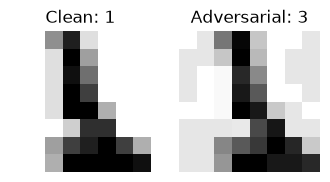

In [5]:
extra_eps = 0.10   # your chosen value, between 0.01 and 0.20

clean_pred = model.predict(X_test)
clean_acc = accuracy_score(y_test, clean_pred)
adv = fgsm(model, X_test, y_test, epsilon=extra_eps)
adv_pred = model.predict(adv)
adv_acc = accuracy_score(y_test, adv_pred)

print("Epsilon:", extra_eps)
print("Clean accuracy:", round(clean_acc, 3))
print("Attacked accuracy:", round(adv_acc, 3))
print("Max perturbation:", round(float(np.max(np.abs(adv - X_test))), 3))

for i in np.where(clean_pred != adv_pred)[0]:
    if clean_pred[i] == y_test[i]:
        print(f"Example index {i}: true {y_test[i]}, clean prediction {clean_pred[i]}, adversarial prediction {adv_pred[i]}")
        fig, ax = plt.subplots(1, 2, figsize=(4, 2))
        ax[0].imshow(X_test[i].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
        ax[0].set_title(f"Clean: {clean_pred[i]}")
        ax[1].imshow(adv[i].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
        ax[1].set_title(f"Adversarial: {adv_pred[i]}")
        for a in ax:
            a.axis('off')
        plt.show()
        break

Epsilon=0.00 | Accuracy=0.962
Epsilon=0.03 | Accuracy=0.907
Epsilon=0.07 | Accuracy=0.791
Epsilon=0.10 | Accuracy=0.624
Epsilon=0.12 | Accuracy=0.516
Epsilon=0.18 | Accuracy=0.204


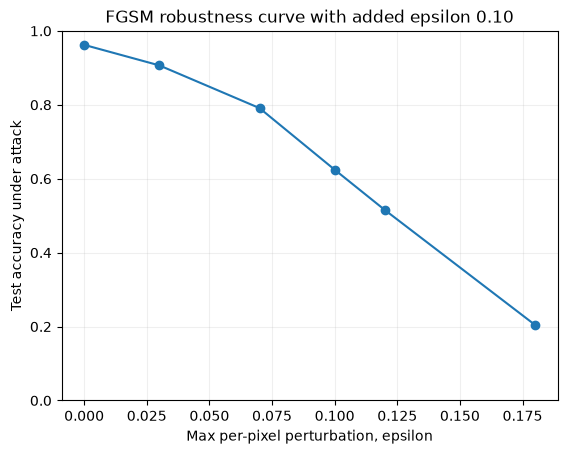

In [6]:
eps_list = [0.00, 0.03, 0.07, 0.10, 0.12, 0.18]
accs = [accuracy_score(y_test, model.predict(fgsm(model, X_test, y_test, epsilon=e))) for e in eps_list]
for e, a in zip(eps_list, accs):
    print(f"Epsilon={e:.2f} | Accuracy={a:.3f}")
plt.plot(eps_list, accs, marker='o')
plt.xlabel('Max per-pixel perturbation, epsilon')
plt.ylabel('Test accuracy under attack')
plt.title('FGSM robustness curve with added epsilon 0.10')
plt.ylim(0, 1); plt.grid(alpha=.2); plt.show()

In [7]:
adv = fgsm(model, X_test, y_test, epsilon=0.10)
change = np.abs(adv - X_test)
print("Largest change:", round(float(change.max()), 3))
print("Share of pixel changes smaller than epsilon:", round(float(np.mean(change < 0.10 - 1e-9)), 3))

Largest change: 0.1
Share of pixel changes smaller than epsilon: 0.29


In [8]:
grad = input_loss_gradient(model, X_test, y_test)
unclipped = X_test + 0.10 * np.sign(grad)
clipped = (unclipped < 0) | (unclipped > 1)
zero_grad = (grad == 0)
print("Share of pixels clipped:", round(float(clipped.mean()), 3))
print("Share of pixels with zero gradient:", round(float(zero_grad.mean()), 3))
print("Share of changes smaller than epsilon:", round(float((change < 0.10 - 1e-9).mean()), 3))


Share of pixels clipped: 0.243
Share of pixels with zero gradient: 0.047
Share of changes smaller than epsilon: 0.29


## Lab 02 Analysis

### Experiment Setup
For this lab, I took the baseline logistic regression model from Lab 01, which scored 0.962 accuracy on the 450 clean test images, and tested how well it holds up against untargeted FGSM attacks. This was a white-box setup, so I had direct access to the model's gradients to generate the perturbations. After applying the changes, I clipped all pixel values to stay within the valid 0 to 1 range.

### What Happened to the Accuracy
Epsilon is the maximum change allowed on each pixel. As I increased it, the model's accuracy dropped steadily (E02_epsilon_table, E02_robustness_curve_6pt):
* At **0.03**, accuracy slipped to **0.907**, a drop of about 5.5 percentage points.
* At **0.07**, it fell to **0.791**, down 17.1 points.
* At **0.10**, it fell to **0.624**, a loss of 33.8 points. I added this value myself because it fills the widest gap in the curve, between 0.07 and 0.12 (E02_extra_epsilon).
* At **0.12**, it fell to **0.516**, down 44.6 points.
* At **0.18**, it fell to **0.204**, a loss of 75.8 points.

I checked the maximum pixel change at epsilon 0.12 and at 0.10, and in both cases it equalled epsilon, so the attack stayed within its bound. I did not run this check for the other epsilon values.

### Looking at the Images
At epsilon 0.12, the model read an 8 as a 5, a 1 as a 3 and a 5 as a 9, while the 0 and the 9 samples were still predicted correctly (E02_image_pairs). At epsilon 0.10, test image 3, which the model had read correctly as a 1, was predicted as a 3. The changes are not invisible. You can see grey noise building up around the strokes of the digits, so a person can still recognise the digit while the model gets it wrong.

### Pixel Clipping Breakdown
At epsilon 0.10, about 29% of the pixel changes were smaller than the full epsilon step. Of the pixels, 24.3% were clipped because the change would have pushed them outside the 0 to 1 range, and 4.7% did not change because the gradient at those pixels was zero (E02_clipping_breakdown).

### Why Clean Accuracy in Lab 01 Was Misleading
Getting 96.2% clean accuracy in Lab 01 gave me a sense of confidence that these results do not support. Clean accuracy only tells me how the model performs on normal, untouched images. It does not show how the model behaves when someone changes the input on purpose, and that is exactly where the accuracy fell.

### What the Curve Shows
The decline is not a straight line. Accuracy fell slowly at small epsilon, at roughly 2 to 3 percentage points per 0.01 up to 0.07, then more steeply, and from about 0.07 onwards the loss stayed close to 5 percentage points per 0.01. One possible explanation is that many test images sit close to the model's decision boundary, but I did not test this, so it remains a guess.

### Limitations of This Test
The images are tiny (8×8) and the model is a simple linear one. The test also assumed a white-box attacker who can edit raw pixels directly, and I used only one random seed and one data split. A drop in untargeted accuracy is not the same as a targeted attack succeeding. I did not test black-box attacks, other model types or targeted attacks, and these numbers do not tell us how a production system would behave.

### Production Controls Beyond Retraining
Retraining on adversarial examples is only one possible control. Lab 04 will test it, and these operational measures would add further layers:
1. **Input validation:** Checking incoming data for the expected size and value range, and for unusual noise patterns, before the model processes it.
2. **Monitoring and alerting:** Logging prediction confidence and watching for sudden spikes in low-confidence predictions or odd query patterns that might mean someone is probing the model.
3. **Human review:** Sending predictions to a person when confidence is low or when the decision carries high risk, instead of letting the system act automatically.